# 🧬 Bird Species Classification — Feature Extraction Module

This notebook extracts numerical feature descriptors representing **Shape (HOG)** and **Texture (LBP)** from the preprocessed images, and saves them into `features.npz` for model training.

### 📁 Pipeline Workflow
```
Dataset/Birds_preprocessed/  <- Standardized 128x128 grayscale images from Step 1
            │
     ┌──────┴──────┐
     ▼             ▼
┌─────────┐   ┌─────────┐
│   HOG   │   │   LBP   │
│ (Shape) │   │(Texture)│
└────┬────┘   └────┬────┘
     │             │
     └──────┬──────┘
            ▼
      features.npz   <- Compact dataset containing (X_hog, X_lbp, y, label_map)
```

### Key Sections:
1. **Environment Setup & Dataset Path.**
2. **HOG & LBP Feature Extractors Definition.**
3. **Visual Demo: Inspecting HOG & LBP features on sample images.**
4. **Batch Processing & Export to `features.npz`.**

---
## ⚙️ Step 1 — Setup & Imports

In [7]:
!pip install opencv-python scikit-image matplotlib numpy

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import hog, local_binary_pattern

# Path to the preprocessed dataset created in notebook 01
DATASET_DIR = "../Dataset/Birds_preprocessed"
OUTPUT_FILE = "features.npz"

---
## 📐 Step 2 — Feature Extraction Functions (HOG & LBP)

In [8]:
def extract_hog_features(image, visualize=False):
    """
    Extracts Histogram of Oriented Gradients (HOG) features representing bird shape.
    """
    if len(image.shape) > 2:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        
    return hog(
        image,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        transform_sqrt=True,
        block_norm='L2-Hys',
        visualize=visualize
    )

def extract_lbp_features(image, radius=3, n_points=24, grid_x=4, grid_y=4):
    """
    Extracts Local Binary Patterns (LBP) histogram features representing feather texture.
    """
    if len(image.shape) > 2:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    lbp = local_binary_pattern(image, n_points, radius, method='uniform')
    n_bins = n_points + 2

    h, w = lbp.shape
    cell_h, cell_w = h // grid_y, w // grid_x
    spatial_hist = []

    for i in range(grid_y):
        for j in range(grid_x):
            cell = lbp[i*cell_h:(i+1)*cell_h, j*cell_w:(j+1)*cell_w]
            hist, _ = np.histogram(cell.ravel(), bins=n_bins, range=(0, n_bins), density=True)
            spatial_hist.extend(hist)
            
    return np.array(spatial_hist)

---
## 🔬 Step 3 — Visual Demo: Inspecting Extracted Features
Visualizes the original preprocessed image alongside its HOG gradient visualization and LBP pattern.

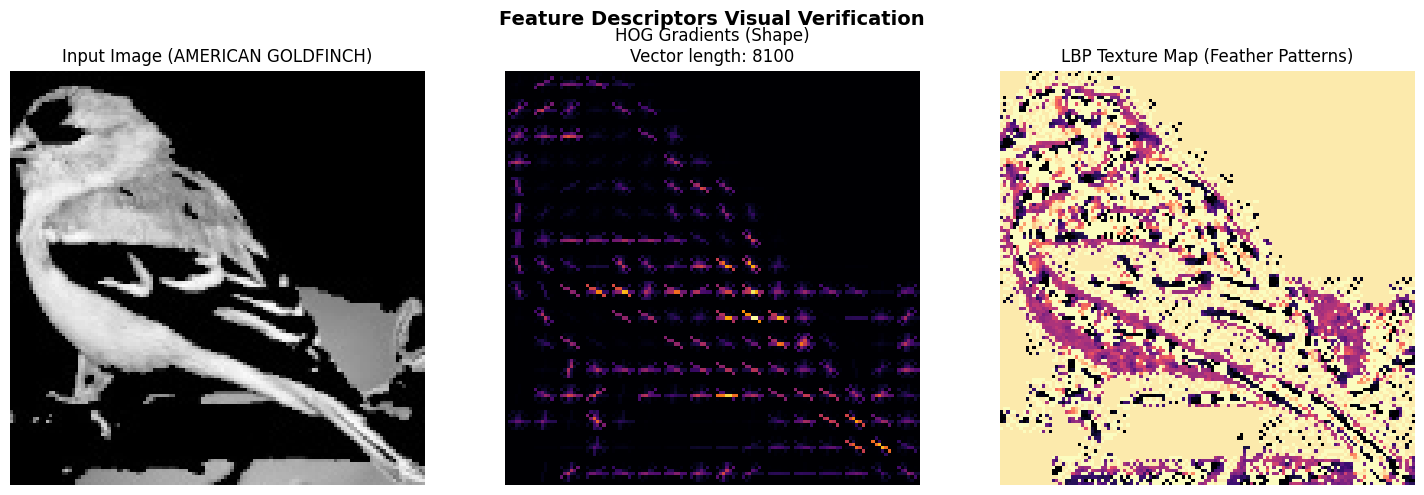

In [9]:
# Pick one sample image to visualize descriptors
sample_img = None
sample_species = ""
for species in os.listdir(DATASET_DIR):
    folder = os.path.join(DATASET_DIR, species)
    if os.path.isdir(folder):
        files = os.listdir(folder)
        if files:
            sample_img = cv2.imread(os.path.join(folder, files[0]), cv2.IMREAD_GRAYSCALE)
            sample_species = species
            break

if sample_img is not None:
    hog_feat, hog_vis = extract_hog_features(sample_img, visualize=True)
    lbp_map = local_binary_pattern(sample_img, P=24, R=3, method='uniform')

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(sample_img, cmap='gray')
    axes[0].set_title(f"Input Image ({sample_species})")
    axes[0].axis('off')

    axes[1].imshow(hog_vis, cmap='inferno')
    axes[1].set_title(f"HOG Gradients (Shape)\nVector length: {len(hog_feat)}")
    axes[1].axis('off')

    axes[2].imshow(lbp_map, cmap='magma')
    axes[2].set_title("LBP Texture Map (Feather Patterns)")
    axes[2].axis('off')

    plt.suptitle("Feature Descriptors Visual Verification", fontsize=14, weight='bold')
    plt.tight_layout()
    plt.show()
else:
    print(f"⚠️ Please run 01_preprocessing.ipynb first to generate images in: {DATASET_DIR}")

---
## 🚀 Step 4 — Batch Process All Images & Save `features.npz`
Iterates through all images in `Dataset/Birds_preprocessed`, calculates both feature vectors, and saves them into `features.npz`.

In [10]:
def extract_and_save_features(dataset_path=DATASET_DIR, output_file=OUTPUT_FILE):
    if not os.path.exists(dataset_path):
        raise FileNotFoundError(f"Dataset path '{dataset_path}' not found! Run 01_preprocessing.ipynb first.")

    species_folders = sorted([f for f in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, f))])
    label_map = {idx: name for idx, name in enumerate(species_folders)}
    
    print(f"Discovered {len(species_folders)} species classes: {label_map}")

    X_hog = []
    X_lbp = []
    y = []

    total_images = 0
    for idx, species in label_map.items():
        species_dir = os.path.join(dataset_path, species)
        img_names = [f for f in os.listdir(species_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
        
        print(f"- Extracting features for: {species} ({len(img_names)} images)...")
        for img_name in img_names:
            img_path = os.path.join(species_dir, img_name)
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            if img is None:
                continue
                
            h_feat = extract_hog_features(img)
            l_feat = extract_lbp_features(img)

            X_hog.append(h_feat)
            X_lbp.append(l_feat)
            y.append(idx)
            total_images += 1

    X_hog = np.array(X_hog)
    X_lbp = np.array(X_lbp)
    y = np.array(y)

    # Save compact archive to disk
    np.savez(output_file, X_hog=X_hog, X_lbp=X_lbp, y=y, label_map=label_map)

    print(f"\n🎉 Feature Extraction Completed for {total_images} images!")
    print(f"- HOG Matrix Shape: {X_hog.shape}")
    print(f"- LBP Matrix Shape: {X_lbp.shape}")
    print(f"- Target Labels Shape: {y.shape}")
    print(f"- Successfully saved to: '{output_file}'")

if __name__ == "__main__":
    extract_and_save_features()

Discovered 6 species classes: {0: 'AMERICAN GOLDFINCH', 1: 'BARN OWL', 2: 'CARMINE BEE-EATER', 3: 'DOWNY WOODPECKER', 4: 'EMPEROR PENGUIN', 5: 'FLAMINGO'}
- Extracting features for: AMERICAN GOLDFINCH (143 images)...
- Extracting features for: BARN OWL (129 images)...
- Extracting features for: CARMINE BEE-EATER (131 images)...
- Extracting features for: DOWNY WOODPECKER (137 images)...
- Extracting features for: EMPEROR PENGUIN (139 images)...
- Extracting features for: FLAMINGO (132 images)...

🎉 Feature Extraction Completed for 811 images!
- HOG Matrix Shape: (811, 8100)
- LBP Matrix Shape: (811, 416)
- Target Labels Shape: (811,)
- Successfully saved to: 'features.npz'
